# Random Forest com as colunas derivadas de `reason`O `reason` de cada run é um texto livre da planilha do parceiro. Ele foi descartadono pré-processamento (`tratamento_final_dos_dados.ipynb`, Célula 1) por serdescritivo demais para virar variável. A auditoria manual mostrou que isso jogafora informação real: **parte dos reasons descreve uma configuração de ensaio quenenhuma das sete variáveis registra** — cobertura sobre o heatsink, nível doventilador, troca de duct, tray ou housing.O custo disso aparece na unificação. A Célula 16 do notebook de tratamento agrupaos runs pelas sete variáveis de configuração e tira a média das temperaturasrepetidas. Como vários runs só se distinguem pelo `reason`, **56 runs viram 32linhas**: ensaios com cobertura e sem cobertura, ou com ventilador em alto e embaixo, são mediados juntos como se fossem a mesma configuração.Com as colunas da auditoria entrando na chave de agrupamento, **56 runs viram 43linhas**: 11 configurações que hoje estão sendo mediadas passam a ser distinguíveis.Este notebook mede se essas 11 linhas a mais, e as 10 colunas que as separam,melhoram o Random Forest. Ele compara três braços:| Braço | Base | Features ||---|---|---|| `A. base atual` | `data/<area>_data.csv` (32 linhas) | 7 variáveis de configuração || `B. base ampliada` | `data/reasons/<area>_data.csv` (43 linhas) | 7 variáveis de configuração || `C. ampliada + reasons` | `data/reasons/<area>_data.csv` (43 linhas) | 7 variáveis + 10 colunas de reason |O braço B existe para separar os dois efeitos. Sem ele, qualquer diferença entreA e C poderia vir só de ter mais linhas, e não das colunas novas. Em B as linhasextras estão lá, mas o modelo não tem como distingui-las: duas linhas com a mesmaconfiguração e temperaturas diferentes viram ruído. **A diferença B → C é oefeito isolado das colunas de reason.**A base vem de `scripts/build_reason_features.py`, que repete o tratamento donotebook original e só acrescenta a conversão do `reason`. Nada em `data/` ésobrescrito: as planilhas novas ficam em `data/reasons/`.

## 1. Bibliotecas e configuração

In [1]:
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split

sns.set_style("whitegrid")
SEMENTE = 42

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DIRETORIO_BASE_ATUAL = RAIZ / "data"
DIRETORIO_BASE_AMPLIADA = RAIZ / "data" / "reasons"

AREAS = [
    "mainback",
    "coil_temps",
    "main_vent_sys",
    "ct_knobs",
    "ipc_comp",
    "ipc_cooling",
    "oven_hmi",
]

VARIAVEIS_CONFIGURACAO = [
    "blower_direction",
    "housing",
    "board_position",
    "run_case",
    "losses",
    "deflector_hole",
    "material_coil_support",
]

# Mesmos parâmetros do Random_for_regre.ipynb, para os números serem comparáveis.
COBERTURA_MINIMA_ALVO = 0.50
N_FOLDS_DESEJADO = 3
PROPORCAO_TREINO = 0.70
PROPORCAO_TESTE = 0.20
PROPORCAO_VERIFICACAO = 0.10

GRADE_HIPERPARAMETROS = {
    "n_estimators": [100, 300, 500, 800],
    "max_depth": [3, 5, 8, 12, 20, None],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", None],
}

GRAFIAS_DIVERGENTES = {
    "blower_direction": {"To back": "To Back", "To front": "To Front"},
    "losses": {"No losses": "No Losses"},
    "run_case": {"Broil Case 2": "Broil C2", "Broil Qual": "Broil Qualitative",
                 "Qualitative": "Broil Qualitative"},
    "housing": {"Open - Updated": "Open"},
}

print(f"Raiz do projeto: {RAIZ}")

Raiz do projeto: C:\INTELI\Projeto3_preditiva\g03


## 2. A auditoria dos reasonsO mapeamento vive em `scripts/build_reason_features.py`, não aqui, porque é eleque gera as planilhas. A célula abaixo importa esse mapeamento e o imprime, para onotebook mostrar exatamente qual regra produziu as colunas que ele vai treinar.Duas decisões da auditoria valem registro, porque não são óbvias na tabela:- **Reasons diferentes podem dividir a mesma coluna.** `Broil 16 CFM`,  `Broil Qualitative - 16 CFM`, `Broil Qualitative (16 cfm) CMC Deflector` e  `... and fan on low` descrevem o mesmo nível de ventilador, então alimentam  `fan_baixo` e têm o mesmo peso no modelo.- **Um reason pode alimentar mais de uma coluna.**  `Run with cover, tested a new duct` descreve duas mudanças ao mesmo tempo, e  marca `com_cobertura_hs` e `duct_novo`.`sem_cobertura_hs` é coluna separada de `com_cobertura_hs` de propósito.`No cover on HS` é uma ausência *medida*, e não a mesma coisa que um run cujoreason não diz nada sobre cobertura. Numa coluna só, os dois casos virariam 0 eessa diferença sumiria.Os reasons descartados (autoexplicativos, ou que não separam nada) ficam com todasas flags em 0: entram no modelo sem peso nenhum, como pedido na auditoria.

In [2]:
sys.path.insert(0, str(RAIZ / "scripts"))
import build_reason_features as auditoria

COLUNAS_REASON = auditoria.COLUNAS_REASON

# Gera data/reasons/ se ainda não existir (ou se faltar alguma área).
faltando = [a for a in AREAS if not (DIRETORIO_BASE_AMPLIADA / f"{a}_data.csv").exists()]
if faltando:
    print(f"Gerando data/reasons/ (faltavam: {', '.join(faltando)})...\n")
    subprocess.run([sys.executable, str(RAIZ / "scripts" / "build_reason_features.py")], check=True)

mapeamento = pd.DataFrame(
    [{"coluna": coluna, "reasons que ativam a coluna": reason}
     for coluna, reasons in auditoria.REASONS_POR_COLUNA.items()
     for reason in reasons]
)

print(f"{len(auditoria.REASONS_POR_COLUNA)} colunas binárias, "
      f"a partir de {mapeamento['reasons que ativam a coluna'].nunique()} reasons distintos:\n")
print(mapeamento.to_string(index=False))

print(f"\n\n{len(auditoria.REASONS_DESCARTADOS)} reasons descartados (todas as flags = 0):\n")
for reason in auditoria.REASONS_DESCARTADOS:
    print(f"   {reason}")

10 colunas binárias, a partir de 17 reasons distintos:

           coluna                      reasons que ativam a coluna
 sem_cobertura_hs                                   No cover on HS
 com_cobertura_hs                     Added a cover above Heatsink
 com_cobertura_hs                                   Run with cover
 com_cobertura_hs                Run with cover, tested a new duct
        fan_baixo Broil Qualitative - 16 CFM (More flow on blower)
        fan_baixo                                     Broil 16 CFM
        fan_baixo         Broil Qualitative (16 cfm) CMC Deflector
        fan_baixo Aluminium Plate Broil wo Cookitop and fan on low
        fan_medio            Aluminium Plate Pyro Blower On Medium
        fan_medio                            Fan velocity 1500 RPM
         fan_alto              Aluminium Plate Pyro Blower On High
         fan_alto                   Aluminium Plate Pyro Blower On
        duct_novo                                Baseline new Duct
      

### Quanto a unificação estava juntandoA célula abaixo mostra o efeito concreto: quais runs caem na mesma linha hoje ecomo as colunas de reason os separam. É a leitura mais direta do que o modeloatual não consegue enxergar.

In [3]:
bruto = pd.read_csv(RAIZ / "data" / "dataset_pre_processado.csv", encoding="utf-8-sig")
bruto["housing"] = bruto["housing"].replace("Open - Updated", "Open")

por_run = bruto.groupby("run_id").agg(
    {**{c: "first" for c in VARIAVEIS_CONFIGURACAO}, "reason": "first"}
).reset_index()

agrupado = por_run.groupby(VARIAVEIS_CONFIGURACAO, dropna=False).agg(
    runs=("run_id", "size"),
    reasons=("reason", lambda s: sorted(set(s))),
).reset_index()

print(f"{len(por_run)} runs -> {len(agrupado)} linhas agrupando só pelas 7 variáveis")
print(f"{len(por_run)} runs -> {len(pd.read_csv(DIRETORIO_BASE_AMPLIADA / 'mainback_data.csv'))} "
      f"linhas agrupando também pelas colunas de reason\n")

print("Configurações que a base atual está mediando junto:\n")
for _, linha in agrupado[agrupado["runs"] > 1].sort_values("runs", ascending=False).iterrows():
    config = " | ".join(str(linha[c]).strip() for c in VARIAVEIS_CONFIGURACAO)
    print(f"  {linha['runs']} runs em 1 linha  [{config}]")
    for reason in linha["reasons"]:
        flags = [c for c, lista in auditoria.REASONS_POR_COLUNA.items() if reason in lista]
        marca = ", ".join(flags) if flags else "-- sem flag (descartado na auditoria)"
        print(f"        {reason:52s} -> {marca}")
    print()

56 runs -> 32 linhas agrupando só pelas 7 variáveis


56 runs -> 43 linhas agrupando também pelas colunas de reason

Configurações que a base atual está mediando junto:

  5 runs em 1 linha  [To front | Closed | Center | Pyro | No losses | Closed | Aluminium]
        Aluminium Plate Broil wo Cookitop                    -> -- sem flag (descartado na auditoria)
        Aluminium Plate Broil wo Cookitop and fan on low     -> fan_baixo
        Aluminium Plate Pyro Blower On                       -> fan_alto
        Aluminium Plate Pyro Blower On High                  -> fan_alto
        Aluminium Plate Pyro Blower On Medium                -> fan_medio

  4 runs em 1 linha  [To back | Open | Center | Broil Qualitative | Simone Losses | Open | Aluminium]
        Added a cover above Heatsink                         -> com_cobertura_hs
        Changed the mainback duct and updated hosuing        -> duct_mainback
        No cover on HS                                       -> sem_cobertura_hs

  4 runs em 1 linha  [To back | Open | Center | Broil

## 3. PipelineAs funções são as mesmas do `Random_for_regre.ipynb` (seleção de alvos porcobertura, padronização de grafias, codificação ordinal, split 70/20/10 e`GridSearchCV`), com uma diferença: `codificar_features` recebe a lista decolunas categóricas e a de colunas binárias separadamente.As 10 colunas de reason **não passam pela codificação ordinal nem pelo`fillna("Nao Informado")`**. Já são 0/1 por construção — tratá-las como categoriaas converteria para texto e de volta para inteiro sem mudar nada, masesconderia que são numéricas.

In [4]:
def identificar_alvos(df, features, nunca_alvo=()):
    """Toda coluna que não é feature nem flag de reason é candidata a alvo.

    `nunca_alvo` existe por causa do braço B: lá as colunas de reason estão no
    arquivo mas ficam de fora das features, e sem excluí-las explicitamente elas
    entrariam como termopar-alvo — o modelo "preveria" as próprias flags, que são
    triviais de acertar, e o MAE médio do braço desabaria por diluição.
    """
    excluidas = set(features) | set(nunca_alvo)
    alvos = [c for c in df.columns if c not in excluidas]
    return [c for c in alvos if not c.startswith("Unnamed:") and not df[c].isna().all()]


def filtrar_alvos_por_cobertura(df, alvos, cobertura_minima):
    """Descarta o SENSOR pouco medido (coluna), e não o run (linha)."""
    return [a for a in alvos if df[a].notna().mean() >= cobertura_minima]


def padronizar_categorias(df, categoricas):
    """Unifica grafias divergentes e transforma nulos em categoria explícita."""
    df = df.copy()
    for variavel, correcoes in GRAFIAS_DIVERGENTES.items():
        if variavel in df.columns:
            df[variavel] = df[variavel].replace(correcoes)
    for variavel in categoricas:
        df[variavel] = df[variavel].fillna("Nao Informado").astype(str)
    return df


def codificar_features(df, categoricas, binarias):
    """Ordinal (0, 1, 2...) nas categóricas; as binárias passam direto."""
    X = df[categoricas + binarias].copy()
    for variavel in categoricas:
        codigos = {c: i for i, c in enumerate(sorted(X[variavel].unique()))}
        X[variavel] = X[variavel].map(codigos)
    return X


def treinar_area(caminho, categoricas, binarias):
    """Pipeline completo de uma planilha: leitura, tratamento, treino e avaliação."""
    df = pd.read_csv(caminho)
    features = categoricas + binarias

    alvos = filtrar_alvos_por_cobertura(
        df, identificar_alvos(df, features, COLUNAS_REASON), COBERTURA_MINIMA_ALVO
    )
    if not alvos:
        raise ValueError(f"{caminho.name}: nenhum termopar com cobertura >= "
                         f"{COBERTURA_MINIMA_ALVO:.0%}")

    tratado = df.dropna(subset=alvos)
    tratado = padronizar_categorias(tratado, categoricas)
    X = codificar_features(tratado, categoricas, binarias)
    Y = tratado[alvos]

    X_treino, X_resto, Y_treino, Y_resto = train_test_split(
        X, Y, train_size=PROPORCAO_TREINO, random_state=SEMENTE)
    X_teste, _, Y_teste, _ = train_test_split(
        X_resto, Y_resto,
        test_size=PROPORCAO_VERIFICACAO / (PROPORCAO_TESTE + PROPORCAO_VERIFICACAO),
        random_state=SEMENTE)

    # Paraleliza a busca, não a floresta: com n_jobs=-1 nos dois, os processos da
    # busca disputam os mesmos núcleos e a célula trava dentro do kernel.
    busca = GridSearchCV(
        estimator=RandomForestRegressor(random_state=SEMENTE, n_jobs=1),
        param_grid=GRADE_HIPERPARAMETROS,
        cv=max(2, min(N_FOLDS_DESEJADO, len(X_treino))),
        scoring="neg_mean_absolute_error",
        n_jobs=-1,
    ).fit(X_treino, Y_treino)

    modelo = busca.best_estimator_
    previsto_teste = modelo.predict(X_teste)
    previsto_treino = modelo.predict(X_treino)

    # Por termopar, para o R² mediano não ser afundado por um alvo ruim.
    mae = [mean_absolute_error(Y_teste.iloc[:, i], previsto_teste[:, i])
           for i in range(len(alvos))]
    rmse = [np.sqrt(mean_squared_error(Y_teste.iloc[:, i], previsto_teste[:, i]))
            for i in range(len(alvos))]
    r2 = [r2_score(Y_teste.iloc[:, i], previsto_teste[:, i]) for i in range(len(alvos))]
    mae_treino = [mean_absolute_error(Y_treino.iloc[:, i], previsto_treino[:, i])
                  for i in range(len(alvos))]

    return {
        "linhas": len(tratado),
        "features": X.shape[1],
        "configuracoes_distintas": len(X.drop_duplicates()),
        "alvos": len(alvos),
        "MAE_C": float(np.mean(mae)),
        "RMSE_C": float(np.mean(rmse)),
        "R2_mediano": float(np.median(r2)),
        "MAE_treino_C": float(np.mean(mae_treino)),
        "modelo": modelo,
        "nomes_features": list(X.columns),
        # Guardados para o gráfico previsto x medido da Seção 8 — não usados em
        # nenhuma métrica desta célula, só na dispersão por ponto individual.
        "Y_teste": Y_teste,
        "previsto_teste": previsto_teste,
        "nomes_alvos": alvos,
    }

print("Funções do pipeline definidas.")

Funções do pipeline definidas.


## 4. Benchmark — os três braços nas sete áreasCada área é treinada três vezes, com a mesma semente, o mesmo split e a mesmagrade de hiperparâmetros (96 combinações, `cv = min(3, linhas de treino)`). Aúnica coisa que muda entre os braços é a base e a lista de features.A célula roda 21 buscas em grade e leva alguns minutos.

In [5]:
BRACOS = {
    "A. base atual":          (DIRETORIO_BASE_ATUAL,    VARIAVEIS_CONFIGURACAO, []),
    "B. base ampliada":       (DIRETORIO_BASE_AMPLIADA, VARIAVEIS_CONFIGURACAO, []),
    "C. ampliada + reasons":  (DIRETORIO_BASE_AMPLIADA, VARIAVEIS_CONFIGURACAO, COLUNAS_REASON),
}

resultados, modelos_c = [], {}
# Guarda a saída completa (inclusive Y_teste/previsto_teste) dos três braços,
# por área — a Seção 8 usa isso para o gráfico previsto x medido.
insumos_por_braco = {nome: {} for nome in BRACOS}

for area in AREAS:
    for nome_braco, (diretorio, categoricas, binarias) in BRACOS.items():
        saida = treinar_area(diretorio / f"{area}_data.csv", categoricas, binarias)
        if nome_braco.startswith("C."):
            modelos_c[area] = saida
        insumos_por_braco[nome_braco][area] = saida
        resultados.append({
            "key_area": area,
            "braco": nome_braco,
            **{k: v for k, v in saida.items() if k not in ("modelo", "nomes_features")},
        })
    print(f"{area} concluída", flush=True)

benchmark = pd.DataFrame(resultados)

# Os três braços têm que prever exatamente os mesmos termopares. Se um braço
# acabar com mais alvos que outro, alguma coluna que não é termopar entrou como
# alvo e as médias deixam de ser comparáveis.
alvos_por_braco = benchmark.groupby("key_area")["alvos"].nunique()
if (alvos_por_braco > 1).any():
    raise AssertionError(
        "Número de alvos diverge entre braços em: "
        f"{alvos_por_braco[alvos_por_braco > 1].index.tolist()}"
    )

print("\n")
print(benchmark.drop(columns=["MAE_treino_C"]).round(3).to_string(index=False))

mainback concluída


coil_temps concluída


main_vent_sys concluída


ct_knobs concluída


ipc_comp concluída


ipc_cooling concluída


oven_hmi concluída




     key_area                 braco  linhas  features  configuracoes_distintas  alvos  MAE_C  RMSE_C  R2_mediano                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                      

### Resumo: o efeito isolado das colunas de reason`A → B` é o efeito de parar de mediar runs diferentes na mesma linha.`B → C` é o efeito das colunas em si, com a base idêntica nos dois lados.

In [6]:
pivo_mae = benchmark.pivot(index="key_area", columns="braco", values="MAE_C")
pivo_r2 = benchmark.pivot(index="key_area", columns="braco", values="R2_mediano")

resumo = pd.DataFrame({
    "MAE_A": pivo_mae["A. base atual"],
    "MAE_B": pivo_mae["B. base ampliada"],
    "MAE_C": pivo_mae["C. ampliada + reasons"],
    "ganho_B_para_C_%": (pivo_mae["B. base ampliada"] - pivo_mae["C. ampliada + reasons"])
                        / pivo_mae["B. base ampliada"] * 100,
    "ganho_A_para_C_%": (pivo_mae["A. base atual"] - pivo_mae["C. ampliada + reasons"])
                        / pivo_mae["A. base atual"] * 100,
    "R2_A": pivo_r2["A. base atual"],
    "R2_B": pivo_r2["B. base ampliada"],
    "R2_C": pivo_r2["C. ampliada + reasons"],
}).loc[AREAS]

print(resumo.round(3).to_string())

melhorou_mae = int((resumo["ganho_B_para_C_%"] > 0).sum())
melhorou_r2 = int((resumo["R2_C"] > resumo["R2_B"]).sum())
print("\nDe B para C (mesma base, mesmos alvos, mesmo split):")
print(f"   MAE de teste melhorou em {melhorou_mae} de {len(resumo)} áreas")
print(f"   R² mediano melhorou em {melhorou_r2} de {len(resumo)} áreas")
print(f"\nMAE médio  A: {resumo['MAE_A'].mean():.3f} C   "
      f"B: {resumo['MAE_B'].mean():.3f} C   C: {resumo['MAE_C'].mean():.3f} C")

               MAE_A   MAE_B   MAE_C  ganho_B_para_C_%  ganho_A_para_C_%   R2_A   R2_B   R2_C
key_area                                                                                     
mainback       3.739   4.145   4.322            -4.267           -15.602 -5.981  0.385  0.468
coil_temps     8.928  10.159  10.146             0.126           -13.641  0.359  0.772  0.783
main_vent_sys  1.855   2.275   2.293            -0.802           -23.579  0.000  0.654  0.729
ct_knobs       1.537   5.433   5.406             0.488          -251.691  0.389 -0.830 -0.689
ipc_comp       5.126   6.068   5.581             8.036            -8.862  0.044 -1.197 -0.730
ipc_cooling    2.508   4.512   4.891            -8.400           -95.047  0.106  0.524  0.549
oven_hmi       2.635   3.718   3.821            -2.767           -45.017 -0.256 -0.113 -0.209

De B para C (mesma base, mesmos alvos, mesmo split):
   MAE de teste melhorou em 3 de 7 áreas
   R² mediano melhorou em 6 de 7 áreas

MAE médio  A: 3.761

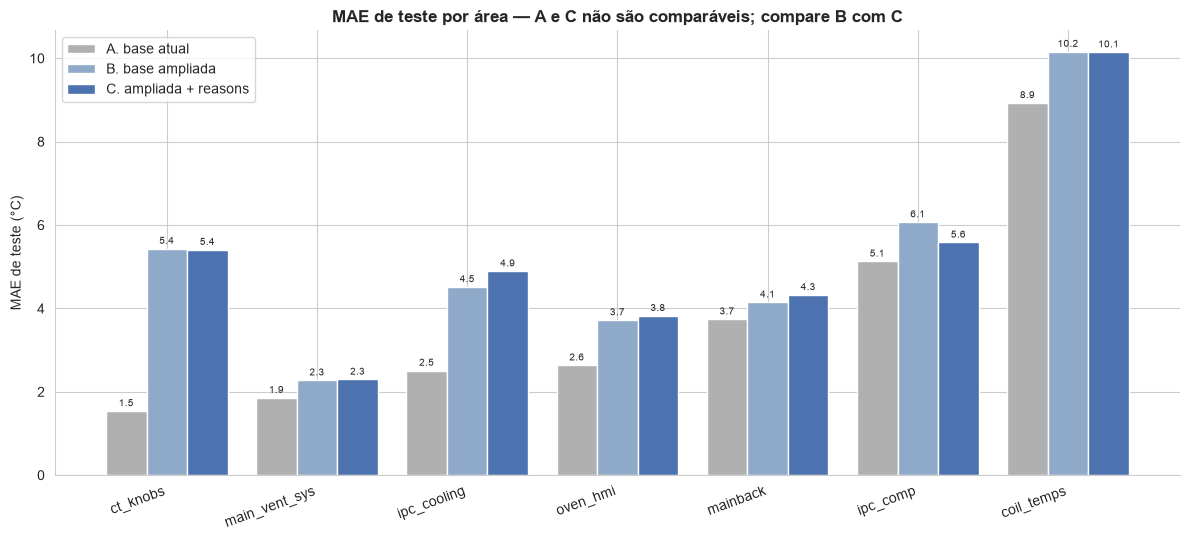

In [7]:
# ============================================================
# GRÁFICO — MAE de teste por área nos três braços
# ============================================================
ordem = resumo.sort_values("MAE_A").index.tolist()
x = np.arange(len(ordem))
largura = 0.27
cores = {"A. base atual": "#B0B0B0", "B. base ampliada": "#8FA9C8",
         "C. ampliada + reasons": "#4C72B0"}

fig, ax = plt.subplots(figsize=(12, 5.5))
for i, (nome_braco, cor) in enumerate(cores.items()):
    valores = pivo_mae.loc[ordem, nome_braco]
    barras = ax.bar(x + (i - 1) * largura, valores, largura, label=nome_braco, color=cor)
    ax.bar_label(barras, fmt="%.1f", padding=2, fontsize=7)

ax.set_xticks(x)
ax.set_xticklabels(ordem, rotation=20, ha="right")
ax.set_ylabel("MAE de teste (°C)")
ax.set_title("MAE de teste por área — A e C não são comparáveis; compare B com C",
             fontsize=12, fontweight="bold")
ax.legend()
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

## 5. As colunas de reason estão sendo usadas?Um ganho de MAE não prova que o modelo aprendeu com as colunas novas: pode vir dosplit. A importância por permutação não cabe aqui (o conjunto de teste tem poucaslinhas), então a leitura é a importância por impureza do próprio Random Forest,somada sobre as 10 colunas de reason e comparada com a soma das 7 variáveis deconfiguração.Se as colunas estivessem sendo ignoradas, a soma ficaria perto de zero. Valelembrar que a importância por impureza favorece variáveis com mais valoresdistintos, o que joga **contra** as colunas binárias — qualquer peso relevanteaqui é um indício conservador.

In [8]:
linhas_importancia = []
for area, saida in modelos_c.items():
    importancias = pd.Series(saida["modelo"].feature_importances_, index=saida["nomes_features"])
    linhas_importancia.append({
        "key_area": area,
        "config_7_vars_%": importancias[VARIAVEIS_CONFIGURACAO].sum() * 100,
        "reasons_10_cols_%": importancias[COLUNAS_REASON].sum() * 100,
        "reason_mais_forte": importancias[COLUNAS_REASON].idxmax(),
        "peso_dele_%": importancias[COLUNAS_REASON].max() * 100,
    })

importancia_por_area = pd.DataFrame(linhas_importancia).set_index("key_area").loc[AREAS]
print(importancia_por_area.round(2).to_string())

media_por_coluna = pd.DataFrame(
    {area: pd.Series(s["modelo"].feature_importances_, index=s["nomes_features"])
     for area, s in modelos_c.items()}
).loc[COLUNAS_REASON].mean(axis=1).sort_values(ascending=False) * 100

print("\n\nImportância média de cada coluna de reason, entre as sete áreas (%):\n")
print(media_por_coluna.round(2).to_string())

               config_7_vars_%  reasons_10_cols_% reason_mais_forte  peso_dele_%
key_area                                                                        
mainback                 69.05              30.95         fan_medio         9.51
coil_temps               98.08               1.92         fan_baixo         1.00
main_vent_sys            95.08               4.92  sem_cobertura_hs         2.39
ct_knobs                 95.63               4.37          fan_alto         3.06
ipc_comp                 78.91              21.09         fan_baixo         6.62
ipc_cooling              92.37               7.63          fan_alto         4.57
oven_hmi                 88.55              11.45         duct_novo         5.40


Importância média de cada coluna de reason, entre as sete áreas (%):

fan_alto             2.83
fan_baixo            2.18
fan_medio            1.92
com_cobertura_hs     1.66
sem_cobertura_hs     1.51
duct_novo            1.19
tray_furada          0.26
tray_simplificada

## 6. Leitura dos resultados### A comparação limpa: B → COs braços B e C usam a mesma base, as mesmas linhas, os mesmos termopares e omesmo split. A única diferença são as 10 colunas. Então `B → C` é o efeitoisolado da auditoria:- **MAE de teste:** melhorou em 3 das 7 áreas — `ipc_comp` (+8,0%), `ct_knobs`  (+0,5%) e `coil_temps` (+0,1%) — e piorou nas outras quatro: `ipc_cooling`  (−8,4%), `mainback` (−4,3%), `oven_hmi` (−2,8%) e `main_vent_sys` (−0,8%). Na  média das áreas, 5,187 °C contra 5,209 °C. Empate.- **R² mediano:** melhorou em 6 das 7 áreas. Os ganhos maiores são em `ipc_comp`  (−1,197 → −0,730) e `ct_knobs` (−0,830 → −0,689), ambas ainda negativas;  `mainback` vai de 0,385 a 0,468 e `main_vent_sys` de 0,654 a 0,729. A única  piora é `oven_hmi` (−0,113 → −0,209).As colunas ajudam o modelo a explicar a variância, mas não reduzem o erroabsoluto. Com 9 linhas no conjunto de teste, diferenças de MAE abaixo de uns 10%estão dentro do ruído do split — nenhum dos dois lados desse empate é conclusivo.### Por que `A → C` não deve ser lido como pioraA tabela mostra o MAE de C pior que o de A em todas as sete áreas, com casosextremos como `ct_knobs` (−252%). Isso não é o modelo piorando: **os dois braçosnão estão prevendo a mesma coisa.**Na base atual, cada linha é a média de até 5 runs. Essa média já suavizou avariação entre ensaios que foram tratados como iguais — inclusive a variaçãocausada pela cobertura e pelo nível do ventilador. Prever a média de 5 ensaios émais fácil do que prever um ensaio. Na base ampliada o alvo está mais perto dorun individual, com a variância de volta.`ct_knobs` é o exemplo mais claro: o MAE sai de 1,537 para 5,406 °C, mas o braçoB — mesma base ampliada, **sem nenhuma coluna nova** — já está em 5,433 °C. Adiferença veio inteira de deixar de mediar runs distintos, e não das colunas dereason.Por isso o número que importa é `B → C`.### As colunas estão sendo usadasA importância por impureza soma entre 1,9% (`coil_temps`) e 31,0% (`mainback`)nas dez colunas de reason. Não é ruído: a métrica favorece variáveis com muitosvalores distintos, o que joga contra colunas binárias, então esses pesos são umpiso.Seis colunas carregam praticamente todo esse peso — justamente as que aparecem emvários runs:`fan_alto` 2,83% · `fan_baixo` 2,18% · `fan_medio` 1,92% · `com_cobertura_hs`1,66% · `sem_cobertura_hs` 1,51% · `duct_novo` 1,19%As outras quatro são quase inertes: `tray_furada` 0,26%, `tray_simplificada`0,16%, `clip_housing` 0,05% e `duct_mainback` 0,00%. Cada uma marca um ou doisruns, e uma árvore raramente tem o que fazer com uma flag que separa uma linha em43. Elas não atrapalham, mas também não sustentam conclusão nenhuma.### O que isso significa para o modeloO ganho concreto da auditoria não está nas métricas, está na **representação**.Sem estas colunas o dataset não tem como responder "e se eu colocar uma coberturasobre o heatsink?" ou "e se o ventilador for para o nível baixo?" — os dois casosestão mediados dentro da mesma linha, e o modelo não tem entrada paradistingui-los. Com elas, essas perguntas passam a existir na base: 11configurações antes indistinguíveis viraram linhas próprias.O preço é o que a tabela mostra: o alvo ficou mais difícil porque deixou de seruma média suavizada. Isso não é degradação do modelo, é o erro real aparecendoonde antes estava escondido pela unificação.**Ressalva de tamanho de amostra.** São 42 a 43 linhas, 30 no treino, 9 no teste,17 features. Nessa escala o R² é instável e nenhuma diferença isolada por áreasustenta decisão. O que sustenta é o padrão: o R² melhora em 6 das 7 áreas, e ascolunas de ventilador e cobertura aparecem com peso consistente nas sete.

---# 7. O que muda na práticaAs seções anteriores mediram MAE e R². Nesta escala de amostra, esses númerosempatam e não decidem nada. Esta seção mostra o que de fato muda — e o que mudanão é a precisão do modelo, é **a pergunta que ele consegue responder**.Os gráficos usam uma rampa sequencial azul para o nível do ventilador (claro =baixo, escuro = alto), porque nível é uma variável ordinal, não categoriassoltas. Os runs cujo reason foi descartado na auditoria aparecem em cinza e commarcador `×`, para não dependerem só da cor.

In [9]:
# ============================================================
# CÉLULA 16 — PREPARO DA DEMONSTRAÇÃO
# Reconstrói os runs individuais (antes da unificação) para o Mainback, que é
# a área onde as colunas de reason pesam mais (31% da importância, Célula 15).
# ============================================================
from matplotlib.lines import Line2D

AREA_DEMO = "Mainback"

# Rampa sequencial: nível do ventilador é ordinal, não categórico.
COR_NIVEL = {
    "Ventilador baixo": "#6baed6",
    "Ventilador médio": "#2171b5",
    "Ventilador alto":  "#08306b",
}
COR_SEM_FLAG = "#9a9a9a"
COR_BASE_ATUAL = "#1a1a1a"

# Os cinco runs que a base atual junta numa linha só. Mesmas sete variáveis de
# configuração, cinco ensaios, níveis de ventilador diferentes.
RUNS_DEMO = ["Run 63", "Run 60", "Run 57", "Run 61", "Run 62"]
NIVEL_DO_RUN = {
    "Run 63": "Ventilador baixo",
    "Run 60": "Ventilador médio",
    "Run 57": "Ventilador alto",
    "Run 61": "Ventilador alto",
    "Run 62": "Sem flag (descartado)",
}

bruto_demo = pd.read_csv(RAIZ / "data" / "dataset_pre_processado.csv", encoding="utf-8-sig")
bruto_demo["housing"] = bruto_demo["housing"].replace("Open - Updated", "Open")
_norm = bruto_demo["losses"].astype("string").str.strip().str.casefold()
bruto_demo.loc[_norm.eq("não informado"), "losses"] = "No losses"

reason_do_run = bruto_demo.groupby("run_id")["reason"].first()
com_flags = auditoria.adicionar_colunas_de_reason(bruto_demo)
com_flags["run_id"] = bruto_demo["run_id"]

_area = com_flags[com_flags["key_area"] == AREA_DEMO]
_area = _area[_area["tc_name"] != auditoria.MAINBACK_TC_EXCLUIDO]
runs_individuais = _area.pivot_table(
    index=["run_id"] + VARIAVEIS_CONFIGURACAO + COLUNAS_REASON,
    columns="tc_name", values="temp", aggfunc="mean",
).reset_index()
runs_individuais.columns.name = None

TERMOPARES = [c for c in runs_individuais.columns
              if c not in ["run_id"] + VARIAVEIS_CONFIGURACAO + COLUNAS_REASON]

grupo_demo = runs_individuais[runs_individuais["run_id"].isin(RUNS_DEMO)]
grupo_demo = grupo_demo.set_index("run_id").loc[RUNS_DEMO]

# Os seis termopares de maior amplitude dentro do grupo.
amplitude_no_grupo = (grupo_demo[TERMOPARES].max() - grupo_demo[TERMOPARES].min())
TCS_DEMO = amplitude_no_grupo.sort_values(ascending=False).head(6).index.tolist()

print(f"Configuração compartilhada pelos {len(RUNS_DEMO)} runs:")
for variavel in VARIAVEIS_CONFIGURACAO:
    print(f"   {variavel:24s} {str(grupo_demo.iloc[0][variavel]).strip()}")

print(f"\nOs {len(RUNS_DEMO)} ensaios que a base atual funde nessa única linha:\n")
for run in RUNS_DEMO:
    print(f"   {run:10s} {NIVEL_DO_RUN[run]:24s} {reason_do_run[run]}")

print(f"\nAmplitude de temperatura dentro do grupo, por termopar (°C):\n")
print(amplitude_no_grupo.sort_values(ascending=False).round(1).to_string())
print(f"\nAmplitude média: {amplitude_no_grupo.mean():.1f} °C   "
      f"máxima: {amplitude_no_grupo.max():.1f} °C")

Configuração compartilhada pelos 5 runs:
   blower_direction         To front
   housing                  Closed
   board_position           Center
   run_case                 Pyro
   losses                   No losses
   deflector_hole           Closed
   material_coil_support    Aluminium

Os 5 ensaios que a base atual funde nessa única linha:

   Run 63     Ventilador baixo         Aluminium Plate Broil wo Cookitop and fan on low
   Run 60     Ventilador médio         Aluminium Plate Pyro Blower On Medium
   Run 57     Ventilador alto          Aluminium Plate Pyro Blower On
   Run 61     Ventilador alto          Aluminium Plate Pyro Blower On High
   Run 62     Sem flag (descartado)    Aluminium Plate Broil wo Cookitop

Amplitude de temperatura dentro do grupo, por termopar (°C):



Storage Drawer (Metal Above)          69.8
Convect Motor Winding                 48.0
Door Lock Motor Ambient 1/2" Below    44.4
ACU Ambient (Hill Only) Top           31.9
Door Lock Microswitch Body            30.8
Power On Indicator Body               24.1
Hot Surface Indicator Body            23.7
L2, Wire, Power Cord                  20.7
Ambient Below Terminal Block          19.0
ACU K8 Housing / Double Line Break    18.9

Amplitude média: 33.1 °C   máxima: 69.8 °C


## 7.1 Cinco ensaios, uma linha sóO gráfico abaixo é o problema inteiro numa imagem. Cada faixa cinza é aamplitude de temperatura **realmente medida** nos cinco ensaios, e cada ponto éum ensaio. O losango preto é o único valor que a base atual entrega ao modelopara essa configuração: a média dos cinco.Onde o losango está longe dos pontos, o modelo atual está aprendendo um númeroque nenhum ensaio produziu.

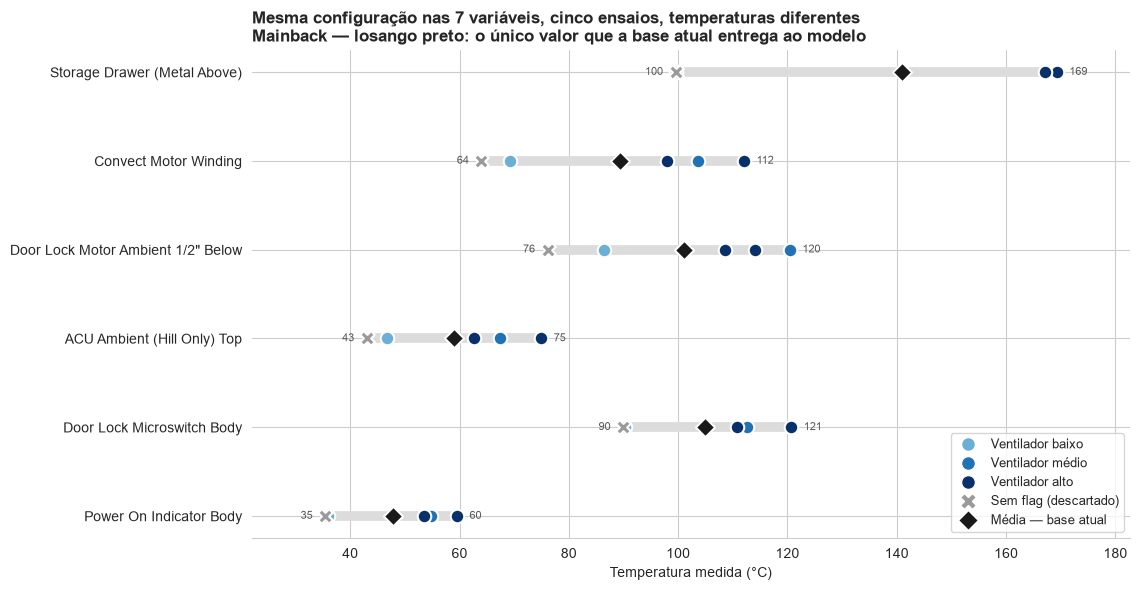

No termopar de maior amplitude (Storage Drawer (Metal Above)), os cinco ensaios vão de 99.5 a 169.3 °C (69.8 °C de diferença).
A base atual resume tudo isso em 140.9 °C — um valor que nenhum dos cinco ensaios mediu.


In [10]:
# ============================================================
# CÉLULA 17 — TEMPERATURAS MEDIDAS x O VALOR ÚNICO DA BASE ATUAL
# ============================================================
def desenhar_grupo(ax, valores_por_run, valor_base_atual, tcs, rotulo_x):
    """Faixa de amplitude + um ponto por run + o valor único da base atual."""
    for i, tc in enumerate(tcs):
        pontos = [valores_por_run[run][tc] for run in RUNS_DEMO]
        ax.plot([min(pontos), max(pontos)], [i, i], color="#dcdcdc", linewidth=7,
                solid_capstyle="round", zorder=1)

        for run in RUNS_DEMO:
            nivel = NIVEL_DO_RUN[run]
            eh_descartado = nivel.startswith("Sem flag")
            ax.scatter(valores_por_run[run][tc], i,
                       marker="X" if eh_descartado else "o",
                       s=110 if eh_descartado else 95,
                       color=COR_SEM_FLAG if eh_descartado else COR_NIVEL[nivel],
                       edgecolor="white", linewidth=1.5, zorder=3)

        ax.scatter(valor_base_atual[tc], i, marker="D", s=95, color=COR_BASE_ATUAL,
                   edgecolor="white", linewidth=1.4, zorder=4)

        # Relevo para os tons claros da rampa: rotula os dois extremos.
        ax.annotate(f"{min(pontos):.0f}", (min(pontos), i), xytext=(-9, 0),
                    textcoords="offset points", ha="right", va="center",
                    fontsize=8, color="#595959")
        ax.annotate(f"{max(pontos):.0f}", (max(pontos), i), xytext=(9, 0),
                    textcoords="offset points", ha="left", va="center",
                    fontsize=8, color="#595959")

    ax.set_yticks(np.arange(len(tcs)))
    ax.set_yticklabels(tcs)
    ax.invert_yaxis()
    ax.set_xlabel(rotulo_x)
    ax.margins(x=0.10)
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)


LEGENDA_DEMO = (
    [Line2D([0], [0], marker="o", color="none", markerfacecolor=cor,
            markeredgecolor="white", markersize=10, label=nivel)
     for nivel, cor in COR_NIVEL.items()]
    + [Line2D([0], [0], marker="X", color="none", markerfacecolor=COR_SEM_FLAG,
              markeredgecolor="white", markersize=11, label="Sem flag (descartado)")]
)

medidos = {run: grupo_demo.loc[run] for run in RUNS_DEMO}
media_do_grupo = grupo_demo[TERMOPARES].mean()

fig, ax = plt.subplots(figsize=(11.5, 6))
desenhar_grupo(ax, medidos, media_do_grupo, TCS_DEMO, "Temperatura medida (°C)")
ax.set_title("Mesma configuração nas 7 variáveis, cinco ensaios, temperaturas diferentes\n"
             f"{AREA_DEMO} — losango preto: o único valor que a base atual entrega ao modelo",
             fontsize=12, fontweight="bold", loc="left")
ax.legend(handles=LEGENDA_DEMO + [
    Line2D([0], [0], marker="D", color="none", markerfacecolor=COR_BASE_ATUAL,
           markeredgecolor="white", markersize=10, label="Média — base atual")],
    loc="lower right", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

pior = amplitude_no_grupo.idxmax()
print(f"No termopar de maior amplitude ({pior}), os cinco ensaios vão de "
      f"{grupo_demo[pior].min():.1f} a {grupo_demo[pior].max():.1f} °C "
      f"({amplitude_no_grupo.max():.1f} °C de diferença).")
print(f"A base atual resume tudo isso em {media_do_grupo[pior]:.1f} °C — "
      "um valor que nenhum dos cinco ensaios mediu.")

## 7.2 O que cada modelo consegue responderO gráfico anterior é sobre o **dado**. Este é sobre o **modelo**.Os dois modelos abaixo são treinados na base inteira, sem separar teste. Isso éproposital: aqui a pergunta não é o quanto o modelo acerta em dados novos (issoé a Seção 4), e sim **quantas respostas distintas ele é capaz de dar** para essaconfiguração. É uma demonstração de capacidade de representação, não degeneralização.O modelo atual devolve um ponto — ele não tem entrada onde receber o nível doventilador. O modelo com as colunas de reason devolve uma resposta por nível.

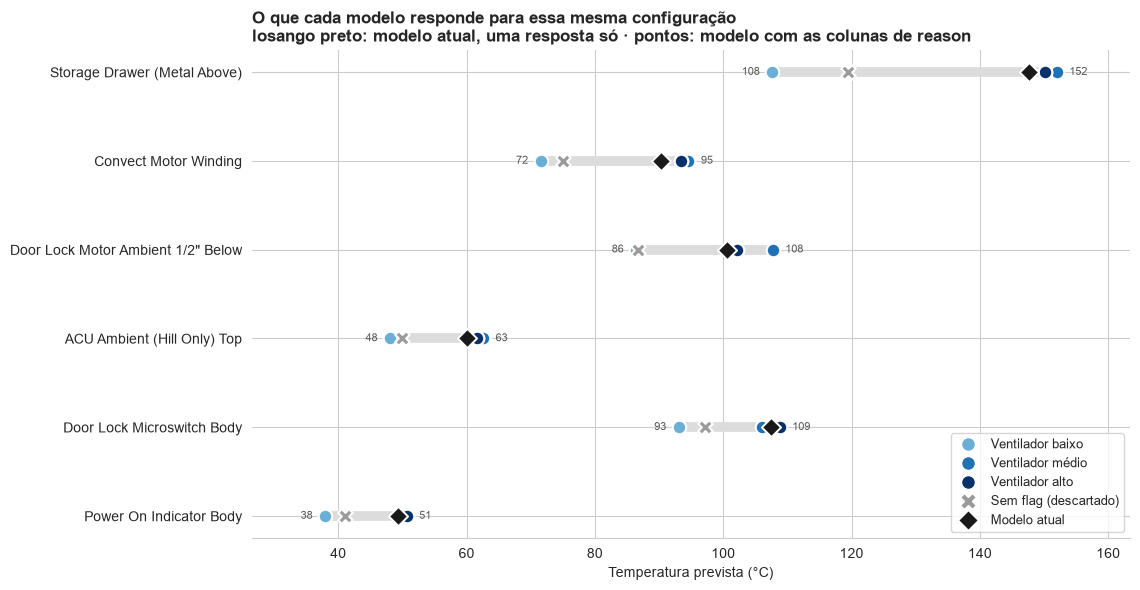

                                    medido_min  medido_max  modelo_atual  reasons_min  reasons_max  faixa_coberta_C
Storage Drawer (Metal Above)              99.5       169.3         147.6        107.6        152.0             44.3
Convect Motor Winding                     64.0       112.0          90.3         71.5         94.6             23.0
Door Lock Motor Ambient 1/2" Below        76.1       120.4         100.6         86.4        107.7             21.3
ACU Ambient (Hill Only) Top               43.0        75.0          60.0         48.1         62.6             14.5
Door Lock Microswitch Body                89.9       120.7         107.4         93.1        108.8             15.8
Power On Indicator Body                   35.4        59.5          49.3         38.0         50.7             12.7

O modelo atual devolve 1 resposta para os cinco ensaios.
O modelo com reasons devolve até 4 respostas distintas, cobrindo em média 21.9 °C de faixa.


In [11]:
# ============================================================
# CÉLULA 18 — O QUE CADA MODELO RESPONDE PARA A MESMA CONFIGURAÇÃO
# Treino na base inteira, de propósito: a pergunta aqui é quantas respostas
# distintas cada modelo consegue dar, não o quanto ele acerta fora da amostra.
# ============================================================
def treinar_para_demonstracao(caminho, binarias):
    """Treina na base inteira e devolve o modelo e os mapas de codificação."""
    base = pd.read_csv(caminho)
    base = padronizar_categorias(base, VARIAVEIS_CONFIGURACAO)
    alvos = filtrar_alvos_por_cobertura(
        base, identificar_alvos(base, VARIAVEIS_CONFIGURACAO + binarias, COLUNAS_REASON),
        COBERTURA_MINIMA_ALVO,
    )
    base = base.dropna(subset=alvos)

    mapas = {v: {c: i for i, c in enumerate(sorted(base[v].unique()))}
             for v in VARIAVEIS_CONFIGURACAO}
    X = base[VARIAVEIS_CONFIGURACAO].apply(lambda col: col.map(mapas[col.name]))
    if binarias:
        X = pd.concat([X, base[binarias]], axis=1)

    modelo = RandomForestRegressor(n_estimators=300, random_state=SEMENTE, n_jobs=1)
    modelo.fit(X, base[alvos])
    return modelo, mapas, alvos


arquivo_demo = f"{AREA_DEMO.lower().replace(' ', '_')}_data.csv"
modelo_atual, mapas_atual, alvos_atual = treinar_para_demonstracao(
    DIRETORIO_BASE_ATUAL / arquivo_demo, [])
modelo_reasons, mapas_reasons, alvos_reasons = treinar_para_demonstracao(
    DIRETORIO_BASE_AMPLIADA / arquivo_demo, COLUNAS_REASON)

# A configuração compartilhada pelos cinco runs, já padronizada como no treino.
config_demo = padronizar_categorias(
    grupo_demo.reset_index()[VARIAVEIS_CONFIGURACAO], VARIAVEIS_CONFIGURACAO
).iloc[0]

linha_atual = pd.DataFrame([{v: mapas_atual[v][config_demo[v]] for v in VARIAVEIS_CONFIGURACAO}])
resposta_atual = pd.Series(modelo_atual.predict(linha_atual)[0], index=alvos_atual)

resposta_reasons = {}
for run in RUNS_DEMO:
    linha = {v: mapas_reasons[v][config_demo[v]] for v in VARIAVEIS_CONFIGURACAO}
    linha.update({flag: int(grupo_demo.loc[run, flag]) for flag in COLUNAS_REASON})
    resposta_reasons[run] = pd.Series(
        modelo_reasons.predict(pd.DataFrame([linha]))[0], index=alvos_reasons)

fig, ax = plt.subplots(figsize=(11.5, 6))
desenhar_grupo(ax, resposta_reasons, resposta_atual, TCS_DEMO,
               "Temperatura prevista (°C)")
ax.set_title("O que cada modelo responde para essa mesma configuração\n"
             "losango preto: modelo atual, uma resposta só · pontos: modelo com as colunas de reason",
             fontsize=12, fontweight="bold", loc="left")
ax.legend(handles=LEGENDA_DEMO + [
    Line2D([0], [0], marker="D", color="none", markerfacecolor=COR_BASE_ATUAL,
           markeredgecolor="white", markersize=10, label="Modelo atual")],
    loc="lower right", frameon=True, fontsize=9)
plt.tight_layout()
plt.show()

comparativo = pd.DataFrame({
    "medido_min": [grupo_demo[tc].min() for tc in TCS_DEMO],
    "medido_max": [grupo_demo[tc].max() for tc in TCS_DEMO],
    "modelo_atual": [resposta_atual[tc] for tc in TCS_DEMO],
    "reasons_min": [min(resposta_reasons[r][tc] for r in RUNS_DEMO) for tc in TCS_DEMO],
    "reasons_max": [max(resposta_reasons[r][tc] for r in RUNS_DEMO) for tc in TCS_DEMO],
}, index=TCS_DEMO)
comparativo["faixa_coberta_C"] = comparativo["reasons_max"] - comparativo["reasons_min"]

print(comparativo.round(1).to_string())
print(f"\nO modelo atual devolve 1 resposta para os cinco ensaios.")
print(f"O modelo com reasons devolve até {len(set(NIVEL_DO_RUN.values()))} respostas distintas, "
      f"cobrindo em média {comparativo['faixa_coberta_C'].mean():.1f} °C de faixa.")

## 7.3 O piso de erro irredutível cai 44,6%A Célula 13 do `Random_for_regre.ipynb` define a régua certa para isso: se amesma configuração produz 80 °C num ensaio e 86 °C em outro, **nenhum modelodeterminístico erra menos que a metade dessa diferença**. Esse piso é umapropriedade dos dados, não do modelo — e é a métrica em que as colunas de reasontêm efeito direto, porque elas desfazem a ambiguidade da entrada.Diferente do MAE de teste, esse número não depende de split nem de semente.

               configs_7v  configs_17f  piso_7v_C  piso_17f_C  queda_%  pior_caso_7v_C  pior_caso_17f_C
key_area                                                                                               
CT Knobs               32           42       1.86        0.73    60.91           13.49             4.21
Oven HMI               32           42       1.13        0.50    55.62            8.34             1.54
Mainback               32           43       3.69        1.65    55.20           33.07            11.16
Main Vent Sys          32           43       2.01        1.05    47.79           18.22             7.80
IPC Comp               32           43       3.14        1.71    45.68           21.92            16.49
IPC Cooling            32           42       2.66        1.48    44.51           19.24             7.09
Coil Temps             32           43       3.55        3.48     2.15           22.28            22.28

Piso médio  —  7 variáveis: 2.58 °C   com reasons: 1.51 °C   qu

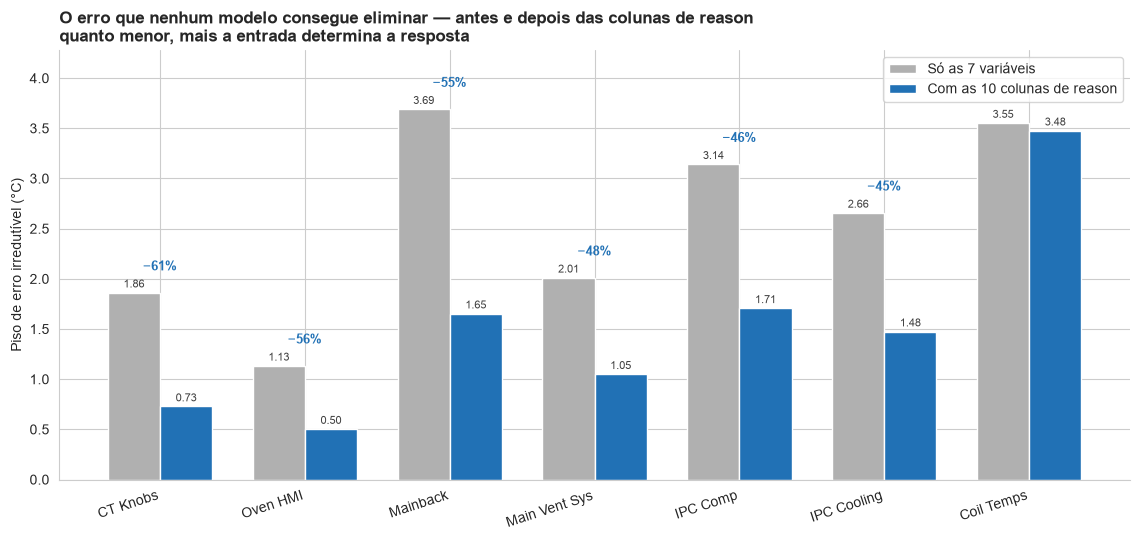

In [12]:
# ============================================================
# CÉLULA 19 — PISO DE ERRO IRREDUTÍVEL, COM E SEM AS COLUNAS DE REASON
# Mesma definição da Célula 13 do Random_for_regre.ipynb, aplicada sobre os
# runs individuais (antes da unificação).
# ============================================================
def piso_de_erro(chave, tabela, alvos):
    """Desvio médio absoluto DENTRO de cada grupo de configurações repetidas."""
    contagem = chave.value_counts()
    desvios = []
    for config in contagem[contagem > 1].index:
        grupo = tabela[chave == config]
        for alvo in alvos:
            valores = grupo[alvo].dropna().values
            if len(valores) > 1:
                desvios.append(np.mean(np.abs(valores - valores.mean())))
    return {
        "configs": int(len(contagem)),
        "repetidas": int((contagem > 1).sum()),
        "piso_C": float(np.mean(desvios)) if desvios else 0.0,
        "pior_caso_C": float(np.max(desvios)) if desvios else 0.0,
    }


linhas_piso = []
for area, area_df in auditoria.dividir_por_key_area(com_flags).items():
    componentes = area_df["tc_name"].dropna().unique()
    wide_area = auditoria.consolidar_igbt(
        auditoria.preencher_nulos(auditoria.tc_names_para_colunas(area_df), componentes))

    alvos_area = [c for c in wide_area.columns
                  if c not in VARIAVEIS_CONFIGURACAO + COLUNAS_REASON]
    alvos_area = [a for a in alvos_area if wide_area[a].notna().mean() >= COBERTURA_MINIMA_ALVO]
    wide_area = wide_area.dropna(subset=alvos_area)

    chave_7 = wide_area[VARIAVEIS_CONFIGURACAO].astype(str).agg("|".join, axis=1)
    chave_17 = wide_area[VARIAVEIS_CONFIGURACAO + COLUNAS_REASON].astype(str).agg("|".join, axis=1)

    sem_reasons = piso_de_erro(chave_7, wide_area, alvos_area)
    com_reasons = piso_de_erro(chave_17, wide_area, alvos_area)
    linhas_piso.append({
        "key_area": area,
        "configs_7v": sem_reasons["configs"],
        "configs_17f": com_reasons["configs"],
        "piso_7v_C": sem_reasons["piso_C"],
        "piso_17f_C": com_reasons["piso_C"],
        "queda_%": (sem_reasons["piso_C"] - com_reasons["piso_C"]) / sem_reasons["piso_C"] * 100,
        "pior_caso_7v_C": sem_reasons["pior_caso_C"],
        "pior_caso_17f_C": com_reasons["pior_caso_C"],
    })

piso = pd.DataFrame(linhas_piso).set_index("key_area").sort_values("queda_%", ascending=False)
print(piso.round(2).to_string())
print(f"\nPiso médio  —  7 variáveis: {piso['piso_7v_C'].mean():.2f} °C   "
      f"com reasons: {piso['piso_17f_C'].mean():.2f} °C   "
      f"queda média: {piso['queda_%'].mean():.1f}%")

# ------------------------------------------------------------------ gráfico
ordem_piso = piso.index.tolist()
x = np.arange(len(ordem_piso))
largura = 0.36

fig, ax = plt.subplots(figsize=(11.5, 5.5))
barras_sem = ax.bar(x - largura / 2, piso["piso_7v_C"], largura,
                    label="Só as 7 variáveis", color="#B0B0B0")
barras_com = ax.bar(x + largura / 2, piso["piso_17f_C"], largura,
                    label="Com as 10 colunas de reason", color="#2171b5")
for barras in (barras_sem, barras_com):
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8, color="#404040")

for i, area in enumerate(ordem_piso):
    queda = piso.loc[area, "queda_%"]
    if queda > 5:
        ax.annotate(f"−{queda:.0f}%", (i, max(piso.loc[area, "piso_7v_C"],
                                              piso.loc[area, "piso_17f_C"])),
                    xytext=(0, 16), textcoords="offset points", ha="center",
                    fontsize=9, fontweight="bold", color="#2171b5")

ax.set_xticks(x)
ax.set_xticklabels(ordem_piso, rotation=18, ha="right")
ax.set_ylabel("Piso de erro irredutível (°C)")
ax.set_title("O erro que nenhum modelo consegue eliminar — antes e depois das colunas de reason\n"
             "quanto menor, mais a entrada determina a resposta",
             fontsize=12, fontweight="bold", loc="left")
ax.legend()
ax.margins(y=0.16)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

## 7.4 Onde as colunas entram na decisão do modeloPor fim, o ranking de importância das 17 features, com as colunas de reasondestacadas. É o mesmo dado da Seção 5, agora ordenado e visto de uma vez: mostraque as colunas de ventilador e cobertura não ficam no rodapé da lista.

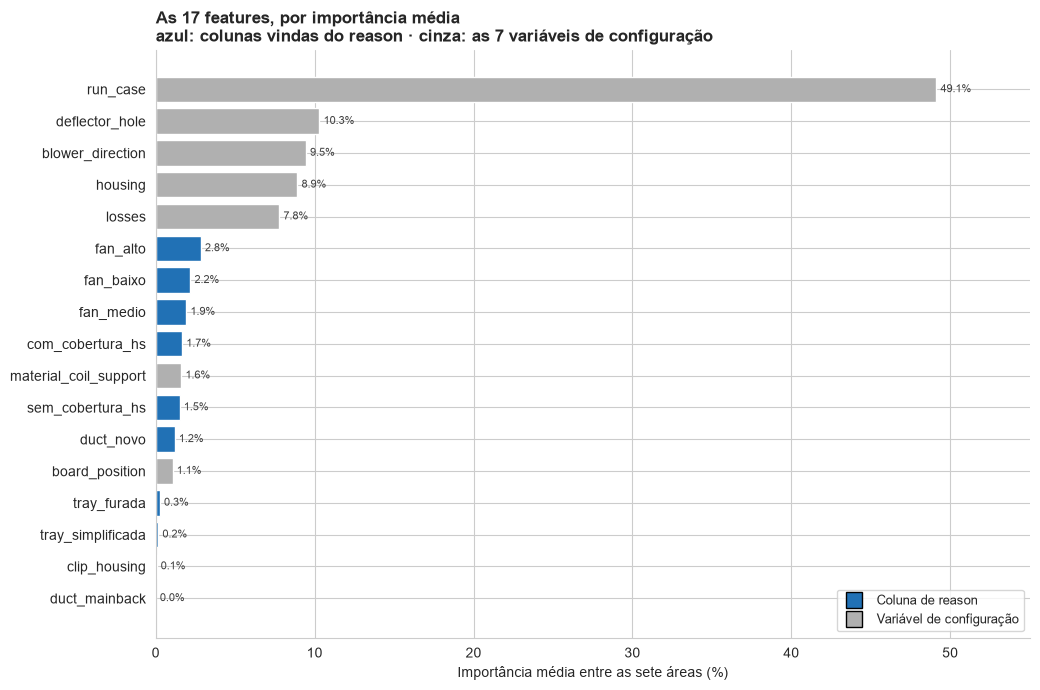

As 10 colunas de reason somam 11.8% da importância média.
A mais forte (fan_alto) é a 6ª de 17 features.


In [13]:
# ============================================================
# CÉLULA 20 — RANKING DE IMPORTÂNCIA, COLUNAS DE REASON DESTACADAS
# ============================================================
importancia_media = pd.DataFrame(
    {area: pd.Series(s["modelo"].feature_importances_, index=s["nomes_features"])
     for area, s in modelos_c.items()}
).mean(axis=1).sort_values() * 100

cores_barras = ["#2171b5" if f in COLUNAS_REASON else "#B0B0B0"
                for f in importancia_media.index]

fig, ax = plt.subplots(figsize=(10.5, 7))
barras = ax.barh(importancia_media.index, importancia_media.values, color=cores_barras)
ax.bar_label(barras, fmt="%.1f%%", padding=3, fontsize=8, color="#404040")

ax.set_xlabel("Importância média entre as sete áreas (%)")
ax.set_title("As 17 features, por importância média\n"
             "azul: colunas vindas do reason · cinza: as 7 variáveis de configuração",
             fontsize=12, fontweight="bold", loc="left")
ax.legend(handles=[
    Line2D([0], [0], marker="s", color="none", markerfacecolor="#2171b5",
           markersize=11, label="Coluna de reason"),
    Line2D([0], [0], marker="s", color="none", markerfacecolor="#B0B0B0",
           markersize=11, label="Variável de configuração"),
], loc="lower right", frameon=True, fontsize=9)
ax.margins(x=0.12)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
plt.tight_layout()
plt.show()

total_reasons = importancia_media[COLUNAS_REASON].sum()
melhor_reason = importancia_media[COLUNAS_REASON].idxmax()
posicao = list(importancia_media.index[::-1]).index(melhor_reason) + 1
print(f"As 10 colunas de reason somam {total_reasons:.1f}% da importância média.")
print(f"A mais forte ({melhor_reason}) é a {posicao}ª de 17 features.")

## 7.5 ResumoO que muda, em uma frase por item:1. **O dado deixa de se contradizer.** Cinco ensaios com temperaturas até 69,8 °C   diferentes estavam registrados como uma única linha, com a média no lugar da   resposta. Agora são linhas distintas.2. **O piso de erro irredutível cai 44,6% em média** (2,58 °C → 1,51 °C), e até   60,9% no CT Knobs. Esse é o chão que nenhum ajuste de hiperparâmetro alcança —   e é onde as colunas têm efeito direto.3. **O modelo passa a responder perguntas que antes não cabiam na entrada.** "E se   eu colocar uma cobertura sobre o heatsink?" e "e se o ventilador for para o   nível baixo?" deixam de ser a mesma pergunta.4. **MAE e R² de teste não decidem nada aqui** — com 9 linhas de teste, a   diferença fica abaixo do ruído do split. Quem decide é o piso, que não depende   de split.O que **não** muda: a precisão do modelo em dados novos continua limitada pelotamanho da base. As colunas de reason não substituem mais ensaios; elas param dejogar fora a informação dos ensaios que já existem.

---# 8. Temperatura prevista x medida — os três braços lado a ladoA Seção 6 comparou MAE e R² em tabela. Esta seção mostra o mesmo resultado comográfico de dispersão — o diagnóstico mais direto que existe para regressão, nomesmo formato da Célula 15 do `Random_for_regre.ipynb`: eixo horizontal é atemperatura **medida**, eixo vertical é a **prevista**, cada ponto é umtermopar de um ensaio do conjunto de teste. Pontos sobre a diagonal sãoprevisões perfeitas; quanto mais longe da diagonal, maior o erro daquele ponto.Os três painéis usam a mesma escala, para a dispersão em torno da diagonal sercomparável a olho nu. Isso é o que os números de MAE já diziam, mas aqui dápara ver **onde** o erro está concentrado, e não só o tamanho médio dele.**Atenção ao ler o painel A.** Ele não está prevendo a mesma coisa que B e C.Em A o alvo é a média de até 5 ensaios (Seção 6); em B e C o alvo é o ensaioindividual. Os pontos de A tendem a ficar mais perto da diagonal não porque omodelo é melhor, e sim porque o alvo que ele persegue já foi suavizado antes dechegar a ele. A comparação que isola o efeito das colunas de reason continuasendo B contra C.

In [14]:
# ============================================================
# CÉLULA 21 — MONTAGEM DOS PONTOS PREVISTO x MEDIDO, POR BRAÇO
# Usa Y_teste e previsto_teste guardados em insumos_por_braco (Célula 7).
# ============================================================
CORES_AREAS = {
    "mainback": "#2a78d6", "coil_temps": "#eb6834", "main_vent_sys": "#1baf7a",
    "ct_knobs": "#eda100", "ipc_comp": "#e87ba4", "ipc_cooling": "#008300",
    "oven_hmi": "#4a3aa7",
}

pontos_por_braco = {}
for nome_braco, por_area in insumos_por_braco.items():
    linhas = []
    for area, saida in por_area.items():
        medido = saida["Y_teste"].values.ravel()
        previsto = np.asarray(saida["previsto_teste"]).ravel()
        valido = ~np.isnan(medido) & ~np.isnan(previsto)
        linhas.append(pd.DataFrame({
            "key_area": area, "medido": medido[valido], "previsto": previsto[valido],
        }))
    pontos_por_braco[nome_braco] = pd.concat(linhas, ignore_index=True)
    pontos_por_braco[nome_braco]["erro_abs"] = (
        pontos_por_braco[nome_braco]["previsto"] - pontos_por_braco[nome_braco]["medido"]
    ).abs()

for nome_braco, pontos in pontos_por_braco.items():
    print(f"{nome_braco:24s} {len(pontos):3d} pontos de teste   "
          f"MAE (recalculado sobre os pontos) = {pontos['erro_abs'].mean():.3f} °C")

A. base atual            366 pontos de teste   MAE (recalculado sobre os pontos) = 4.334 °C
B. base ampliada         488 pontos de teste   MAE (recalculado sobre os pontos) = 5.535 °C
C. ampliada + reasons    488 pontos de teste   MAE (recalculado sobre os pontos) = 5.418 °C


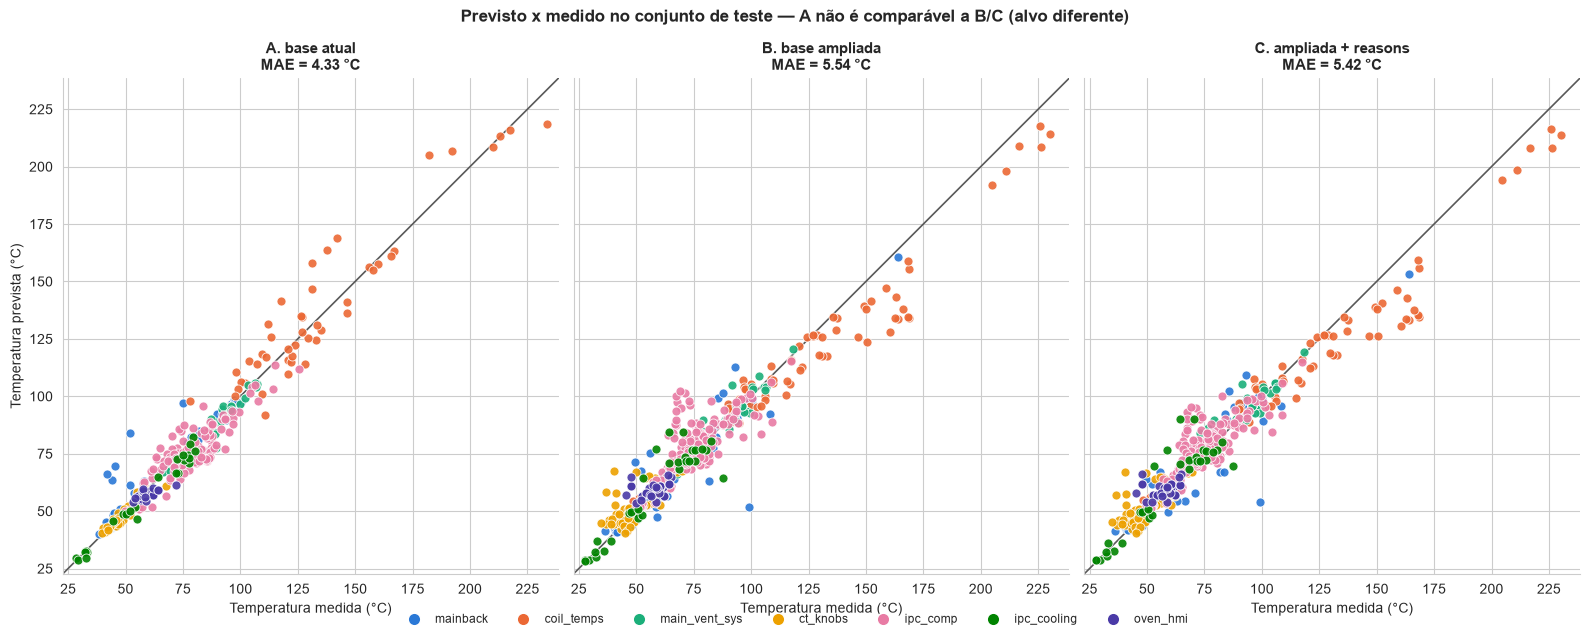

In [15]:
# ============================================================
# CÉLULA 22 — DISPERSÃO PREVISTO x MEDIDO, TRÊS PAINÉIS NA MESMA ESCALA
# ============================================================
todos_os_pontos = pd.concat(pontos_por_braco.values(), ignore_index=True)
limite_min = min(todos_os_pontos["medido"].min(), todos_os_pontos["previsto"].min()) - 5
limite_max = max(todos_os_pontos["medido"].max(), todos_os_pontos["previsto"].max()) + 5

fig, eixos = plt.subplots(1, 3, figsize=(16, 5.8), sharex=True, sharey=True)

for eixo, nome_braco in zip(eixos, BRACOS):
    pontos = pontos_por_braco[nome_braco]
    eixo.plot([limite_min, limite_max], [limite_min, limite_max],
              color="#595959", linewidth=1.2, zorder=1)
    for area, cor in CORES_AREAS.items():
        subset = pontos[pontos["key_area"] == area]
        eixo.scatter(subset["medido"], subset["previsto"], s=42, color=cor,
                     edgecolor="white", linewidth=0.6, alpha=0.9, zorder=2)

    mae_braco = pontos["erro_abs"].mean()
    eixo.set_title(f"{nome_braco}\nMAE = {mae_braco:.2f} °C", fontsize=11, fontweight="bold")
    eixo.set_xlabel("Temperatura medida (°C)")
    eixo.set_xlim(limite_min, limite_max)
    eixo.set_ylim(limite_min, limite_max)
    eixo.set_aspect("equal", adjustable="box")
    for lado in ("top", "right"):
        eixo.spines[lado].set_visible(False)

eixos[0].set_ylabel("Temperatura prevista (°C)")

legenda_areas = [Line2D([0], [0], marker="o", color="none", markerfacecolor=cor,
                        markeredgecolor="white", markersize=9, label=area)
                 for area, cor in CORES_AREAS.items()]
fig.legend(handles=legenda_areas, loc="lower center", ncol=7, frameon=False,
           fontsize=8.5, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Previsto x medido no conjunto de teste — A não é comparável a B/C (alvo diferente)",
             fontsize=12, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 8.1 Leitura do gráfico- **B e C têm a mesma dispersão em torno da diagonal**, porque é a mesma  comparação isolada da Seção 6: mesma base, mesmos ensaios, mesmo split. As  colunas de reason não fecham nem abrem a nuvem de pontos de forma visível —  o que já era esperado pelo empate no MAE.- **A parece mais apertado em torno da diagonal**, mas por um motivo que não é  mérito do modelo: ali o alvo é uma média de até 5 ensaios, que já é mais fácil  de acertar do que um ensaio isolado. Comparar a dispersão de A com a de B/C  seria comparar acertar a média de uma turma com acertar a nota de um aluno.- **Os pontos fora da diagonal em B e C não são erro do reason** — eles já  existiam no problema. O que mudou foi o modelo passar a enxergar a  configuração completa (Seção 7), não o tamanho do erro por ponto individual.Este gráfico é o mesmo resultado da Seção 6 (empate no MAE entre B e C), só quepor ponto individual em vez de por média. Nenhuma leitura nova nasce aqui — eleexiste para tornar visível o que a tabela de números já dizia.